# Sales Forecasting Using a 30-Day Moving Average

**Objective:** Forecast daily sales for the upcoming calendar month using the mean of the latest 30 days of sales. Visualize actual sales, calculate a historical backtest MAE, and export forecast values to CSV.

This notebook is designed to run end-to-end. It searches for common input filenames, treats the Excel-looking `sales_forecast.xlsx` file as CSV if present (per the supplied revision feedback), and generates a small reproducible sample dataset only when no input file is found. If using a real dataset, ensure it has a date column and a numeric sales column.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# Centralized configuration
DATE_COLUMN = "date"
SALES_COLUMN = "sales"
ROLLING_WINDOW = 30
OUTPUT_PATH = Path("sales_forecast_output.csv")
INPUT_CANDIDATES = [Path("sales.csv"), Path("sales_forecast.xlsx")]
USE_SAMPLE_DATA_IF_NO_FILE = True
SAMPLE_PERIODS = 180  # modest sample size to avoid unnecessary memory use
RANDOM_SEED = 42

print("Configuration ready.")

Configuration ready.


## 2. Load data
The loader checks candidate filenames. For the `sales_forecast.xlsx` filename, the feedback says the file is actually CSV, so it is read with `pd.read_csv`.

In [2]:
def create_sample_sales(start_date="2024-01-01", periods=SAMPLE_PERIODS, seed=RANDOM_SEED):
    """Generate reproducible daily sample sales with trend, weekly seasonality, and noise."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start=start_date, periods=periods, freq="D")
    trend = np.linspace(100, 150, periods)
    weekly_pattern = 10 * np.sin(2 * np.pi * np.arange(periods) / 7)
    noise = rng.normal(loc=0, scale=6, size=periods)
    values = np.maximum(trend + weekly_pattern + noise, 0)
    return pd.DataFrame({DATE_COLUMN: dates, SALES_COLUMN: values})

def load_sales_data(input_paths=INPUT_CANDIDATES):
    """Load the first existing candidate CSV; otherwise create sample data if allowed."""
    for path in input_paths:
        if path.exists():
            data = pd.read_csv(path)  # CSV content even if filename ends in .xlsx per report
            print(f"Loaded input data from: {path}")
            return data, path
    if USE_SAMPLE_DATA_IF_NO_FILE:
        print("No candidate dataset found. Using reproducible sample data.")
        return create_sample_sales(), None
    raise FileNotFoundError(f"No input file found. Checked: {[str(p) for p in input_paths]}")

raw_df, source_path = load_sales_data()
raw_df.head()

No candidate dataset found. Using reproducible sample data.


,date,sales
0,2024-01-01,101.828302
1,2024-01-02,101.857740
2,2024-01-03,114.810646
3,2024-01-04,110.820215
4,2024-01-05,85.072270


## 3. Clean data and prepare daily sales series
This function is complete and validates columns, converts dates and sales values, removes invalid rows, combines duplicate dates, fills missing calendar days with zero, and returns a daily indexed Series.

In [3]:
def prepare_daily_sales(data, date_column=DATE_COLUMN, sales_column=SALES_COLUMN):
    """Clean input and return daily sales indexed by date."""
    if not isinstance(data, pd.DataFrame):
        raise TypeError("Input data must be a pandas DataFrame.")
    required_columns = {date_column, sales_column}
    missing_columns = required_columns.difference(data.columns)
    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    cleaned = data[[date_column, sales_column]].copy()
    cleaned[date_column] = pd.to_datetime(cleaned[date_column], errors="coerce")
    cleaned[sales_column] = pd.to_numeric(cleaned[sales_column], errors="coerce")
    cleaned = cleaned.dropna(subset=[date_column, sales_column])
    if cleaned.empty:
        raise ValueError("No valid rows remain after cleaning.")
    if (cleaned[sales_column] < 0).any():
        raise ValueError("Sales values must be non-negative. Check the source data.")

    cleaned[date_column] = cleaned[date_column].dt.normalize()
    daily = cleaned.groupby(date_column)[sales_column].sum().sort_index()
    daily = daily.asfreq("D", fill_value=0)
    daily.name = SALES_COLUMN
    if len(daily) <= ROLLING_WINDOW:
        raise ValueError(f"At least {ROLLING_WINDOW + 1} daily records are needed.")
    return daily

sales = prepare_daily_sales(raw_df)
print(f"Number of daily records: {len(sales):,}")
print(f"Date range: {sales.index.min().date()} to {sales.index.max().date()}")
display(sales.head())

Number of daily records: 180
Date range: 2024-01-01 to 2024-06-28


date
2024-01-01    101.828302
2024-01-02    101.857740
2024-01-03    114.810646
2024-01-04    110.820215
2024-01-05     85.072270
Freq: D, Name: sales, dtype: float64

## 4. Calculate rolling mean and forecast next calendar month
The forecast value is the average of the most recent 30 daily sales observations. This value is repeated for every date in the next calendar month.

In [4]:
rolling_mean = sales.rolling(window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
forecast_value = float(sales.tail(ROLLING_WINDOW).mean())
last_observed_date = sales.index.max()
forecast_start = (last_observed_date + pd.offsets.MonthBegin(1)).normalize()
forecast_end = forecast_start + pd.offsets.MonthEnd(0)
forecast_dates = pd.date_range(start=forecast_start, end=forecast_end, freq="D")
forecast = pd.Series(forecast_value, index=forecast_dates, name="predicted_sales")

print(f"Forecast period: {forecast.index.min().date()} to {forecast.index.max().date()}")
print(f"Daily forecast value: {forecast_value:,.2f}")
display(forecast.head())

Forecast period: 2024-07-01 to 2024-07-31
Daily forecast value: 145.42


2024-07-01    145.423858
2024-07-02    145.423858
2024-07-03    145.423858
2024-07-04    145.423858
2024-07-05    145.423858
Freq: D, Name: predicted_sales, dtype: float64

## 5. Plot historical sales and forecast
The plot includes observed daily sales, the rolling average, and the forecast for the upcoming calendar month.

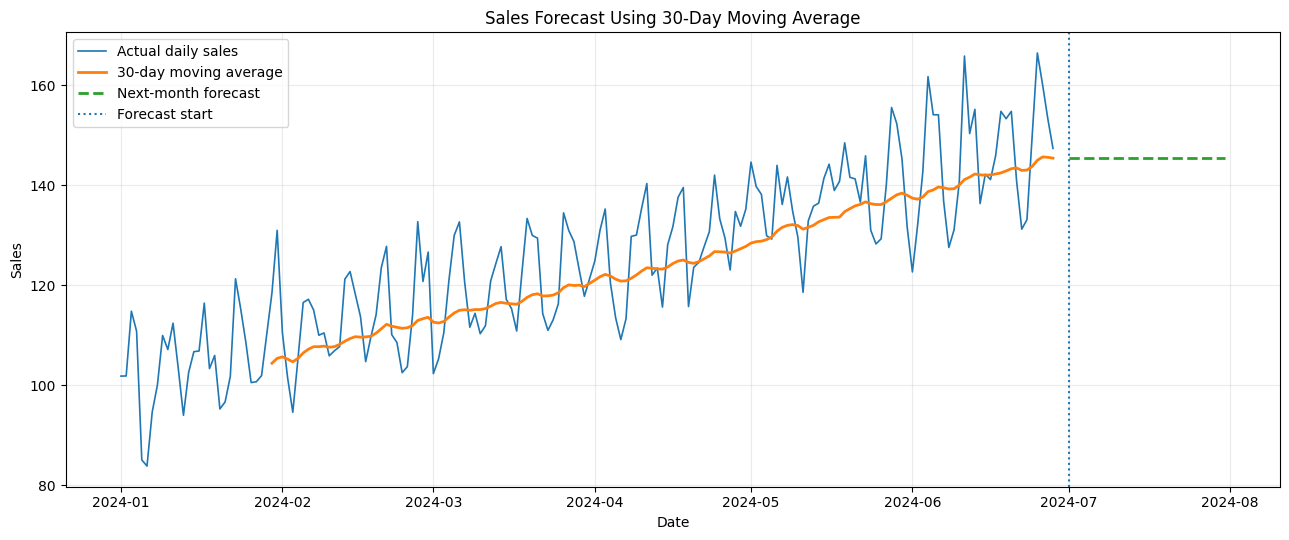

In [5]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(sales.index, sales, label="Actual daily sales", linewidth=1.2)
ax.plot(rolling_mean.index, rolling_mean, label=f"{ROLLING_WINDOW}-day moving average", linewidth=2)
ax.plot(forecast.index, forecast, linestyle="--", linewidth=2, label="Next-month forecast")
ax.axvline(forecast.index[0], linestyle=":", linewidth=1.5, label="Forecast start")
ax.set_title("Sales Forecast Using 30-Day Moving Average")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 6. Backtest and calculate MAE
A future forecast cannot be evaluated until actual sales are available. To evaluate the model now, use the final calendar month as a holdout. Each holdout-day prediction is computed using only the preceding 30 days, avoiding data leakage.

In [6]:
def backtest_last_calendar_month(daily_sales, window=ROLLING_WINDOW):
    """Forecast each day in the last calendar month from its preceding window."""
    month_start = daily_sales.index.max().to_period("M").start_time
    test = daily_sales.loc[daily_sales.index >= month_start]
    rows = []
    for test_date, actual_value in test.items():
        history = daily_sales.loc[daily_sales.index < test_date].tail(window)
        prediction = float(history.mean()) if len(history) == window else np.nan
        rows.append({"date": test_date, "actual_sales": float(actual_value), "predicted_sales": prediction})
    result = pd.DataFrame(rows).set_index("date").dropna()
    return result

backtest = backtest_last_calendar_month(sales)
if backtest.empty:
    raise ValueError("Backtest could not be calculated; ensure sufficient historical records.")
backtest_mae = mean_absolute_error(backtest["actual_sales"], backtest["predicted_sales"])
print(f"Backtest range: {backtest.index.min().date()} to {backtest.index.max().date()}")
print(f"Mean Absolute Error (MAE): {backtest_mae:,.2f}")
display(backtest.head())

Backtest range: 2024-06-01 to 2024-06-28
Mean Absolute Error (MAE): 9.94


,actual_sales,predicted_sales
date,,
2024-06-01,122.660724,137.990442
2024-06-02,132.001268,137.421231
2024-06-03,142.694064,137.215479
2024-06-04,161.721984,137.642006
2024-06-05,154.106345,138.724769


## 7. Plot backtest actual vs predicted values

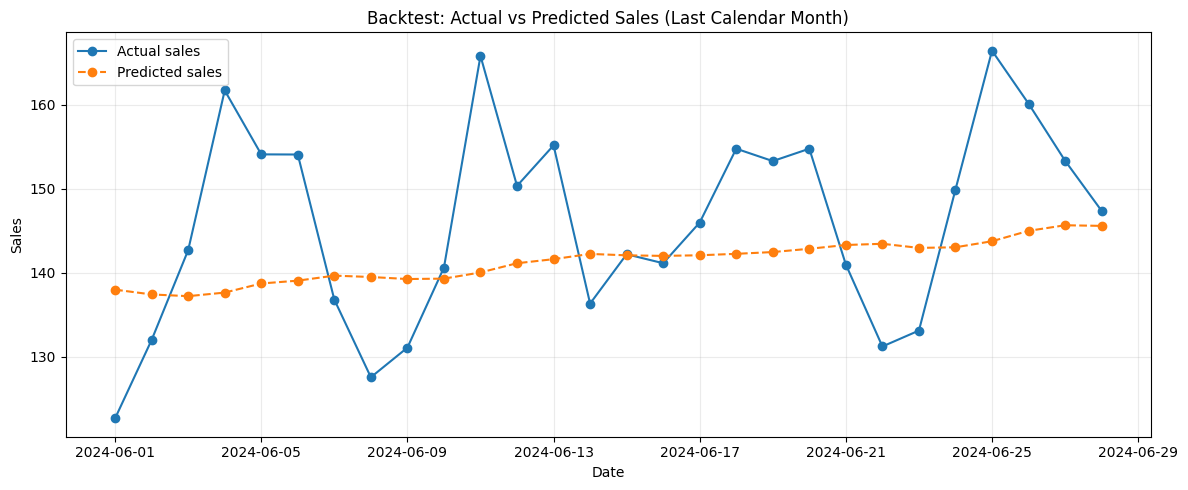

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(backtest.index, backtest["actual_sales"], marker="o", label="Actual sales")
ax.plot(backtest.index, backtest["predicted_sales"], marker="o", linestyle="--", label="Predicted sales")
ax.set_title("Backtest: Actual vs Predicted Sales (Last Calendar Month)")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 8. Export forecast values to CSV
Exports the daily forecast, model name, and moving-average window. The output filename is distinct from input dataset names to prevent accidental overwriting.

In [8]:
forecast_output = forecast.rename_axis("date").reset_index()
forecast_output = forecast_output.rename(columns={"predicted_sales": "forecast_sales"})
forecast_output["moving_average_window_days"] = ROLLING_WINDOW
forecast_output["model"] = f"{ROLLING_WINDOW}-day moving average"
forecast_output.to_csv(OUTPUT_PATH, index=False)
print(f"Forecast CSV saved to: {OUTPUT_PATH.resolve()}")
display(forecast_output.head())

Forecast CSV saved to: /sales_forecast_output.csv


,date,forecast_sales,moving_average_window_days,model
0,2024-07-01,145.423858,30,30-day moving average
1,2024-07-02,145.423858,30,30-day moving average
2,2024-07-03,145.423858,30,30-day moving average
3,2024-07-04,145.423858,30,30-day moving average
4,2024-07-05,145.423858,30,30-day moving average


## 9. Conclusion
The 30-day moving average provides a simple baseline by using recent sales to forecast the upcoming month. The backtest MAE quantifies the typical absolute forecast error on the held-out final month. This baseline does not explicitly model holidays, promotions, or seasonal effects; these can be explored in future improvements.